In [1]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

In [2]:
# Подгружаем модель
model = YOLO('yolov8n-seg.pt')

In [3]:
# Выводим информацию о картинке
results = model('0a19729c.jpg', retina_masks=True)


image 1/1 C:\Users\Alex\PycharmProjects\JupyterProject\dz_15\0a19729c.jpg: 416x640 1 cat, 46.7ms
Speed: 2.7ms preprocess, 46.7ms inference, 4.6ms postprocess per image at shape (1, 3, 416, 640)


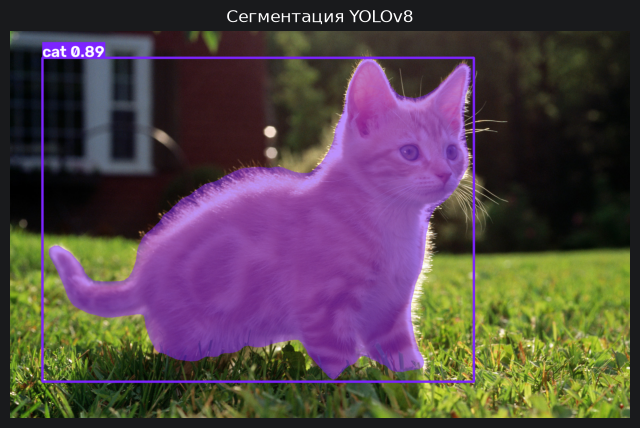

In [4]:
# Показываем изображение с наложенной маской
annotated_image = results[0].plot()
annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(annotated_image)
plt.title('Сегментация YOLOv8')
plt.axis('off')
plt.show()

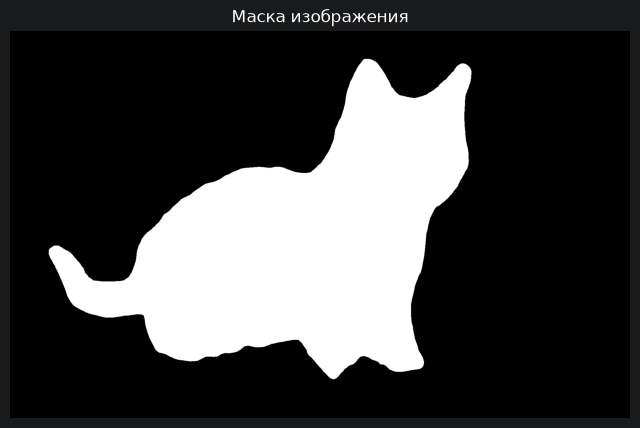

(1200, 1920)

In [5]:
# Выводим отдельно маску от изображения
mask = results[0].masks.data[0].cpu().numpy()

plt.figure(figsize=(8, 6))
plt.imshow(mask, cmap='gray')
plt.title('Маска изображения')
plt.axis('off')
plt.show()
mask.shape

In [6]:
# Сравниваем размеры
original = results[0].orig_img
print(original.shape, mask.shape)
print(mask.dtype, mask.min(), mask.max())

(1200, 1920, 3) (1200, 1920)
uint8 0 1


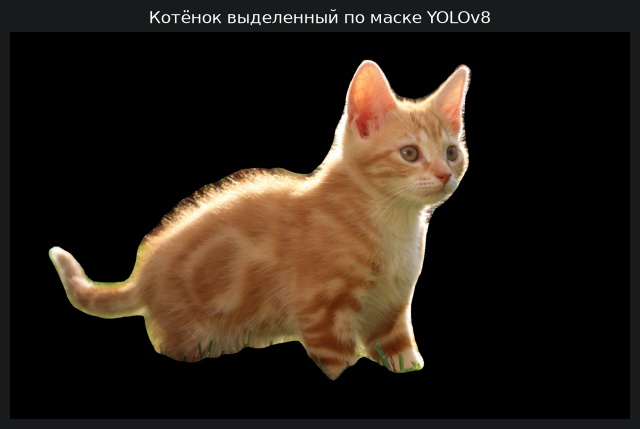

In [7]:
# Выводим котенка на черном фоне
cat_image = cv2.bitwise_and(original, original, mask=mask)
cat_image = cv2.cvtColor(cat_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(cat_image)
plt.title('Котёнок выделенный по маске YOLOv8')
plt.axis('off')
plt.show()

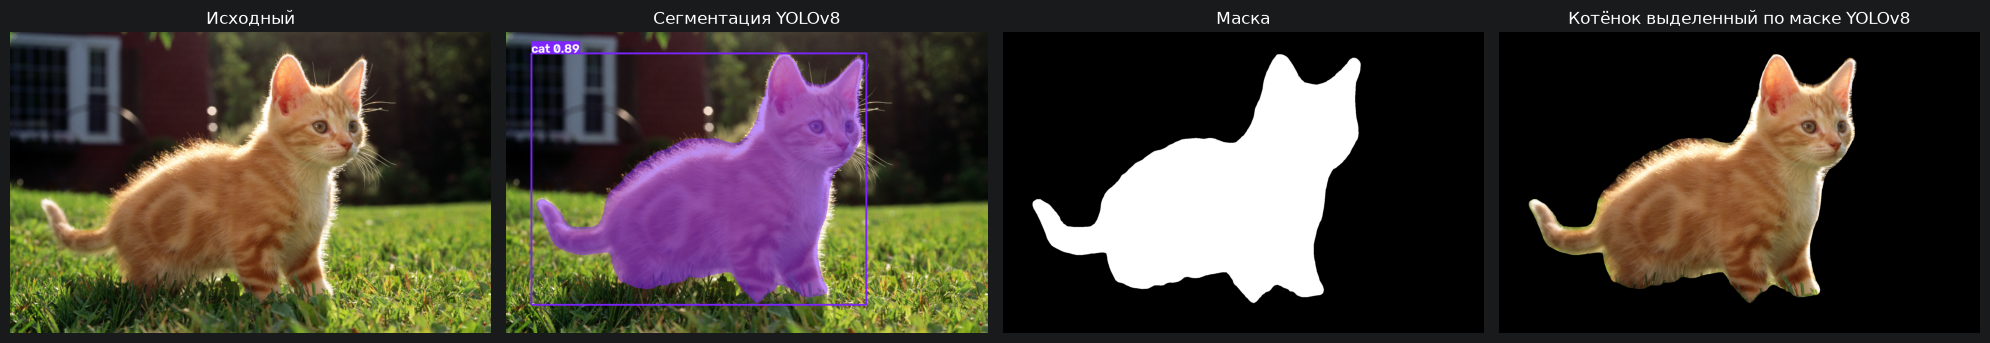

In [8]:
# Выводим вместе исходный вид, результат YOLO с наложенной маской, маску и выделенный котенок
original_rgb = cv2.cvtColor(results[0].orig_img, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

ax[0].imshow(original_rgb)
ax[0].set_title('Исходный')
ax[0].axis('off')

ax[1].imshow(annotated_image)
ax[1].set_title('Сегментация YOLOv8')
ax[1].axis('off')

ax[2].imshow(mask, cmap='gray')
ax[2].set_title('Маска')
ax[2].axis('off')

ax[3].imshow(cat_image)
ax[3].set_title('Котёнок выделенный по маске YOLOv8')
ax[3].axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Возьмем другое изображение с несколькими обьектами
results2 = model('0e5a8b.jpg', retina_masks=True)


image 1/1 C:\Users\Alex\PycharmProjects\JupyterProject\dz_15\0e5a8b.jpg: 480x640 6 persons, 1 sports ball, 49.4ms
Speed: 1.2ms preprocess, 49.4ms inference, 15.1ms postprocess per image at shape (1, 3, 480, 640)


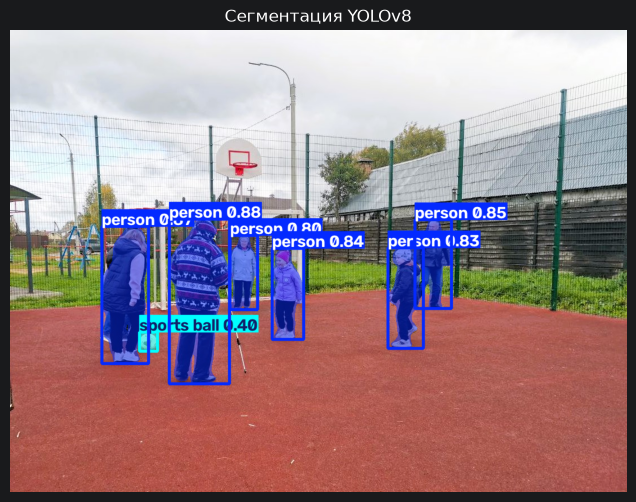

In [10]:
# Показываем изображение с наложенной маской
annotated_image2 = results2[0].plot()
annotated_image2 = cv2.cvtColor(annotated_image2, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(annotated_image2)
plt.title('Сегментация YOLOv8')
plt.axis('off')
plt.show()

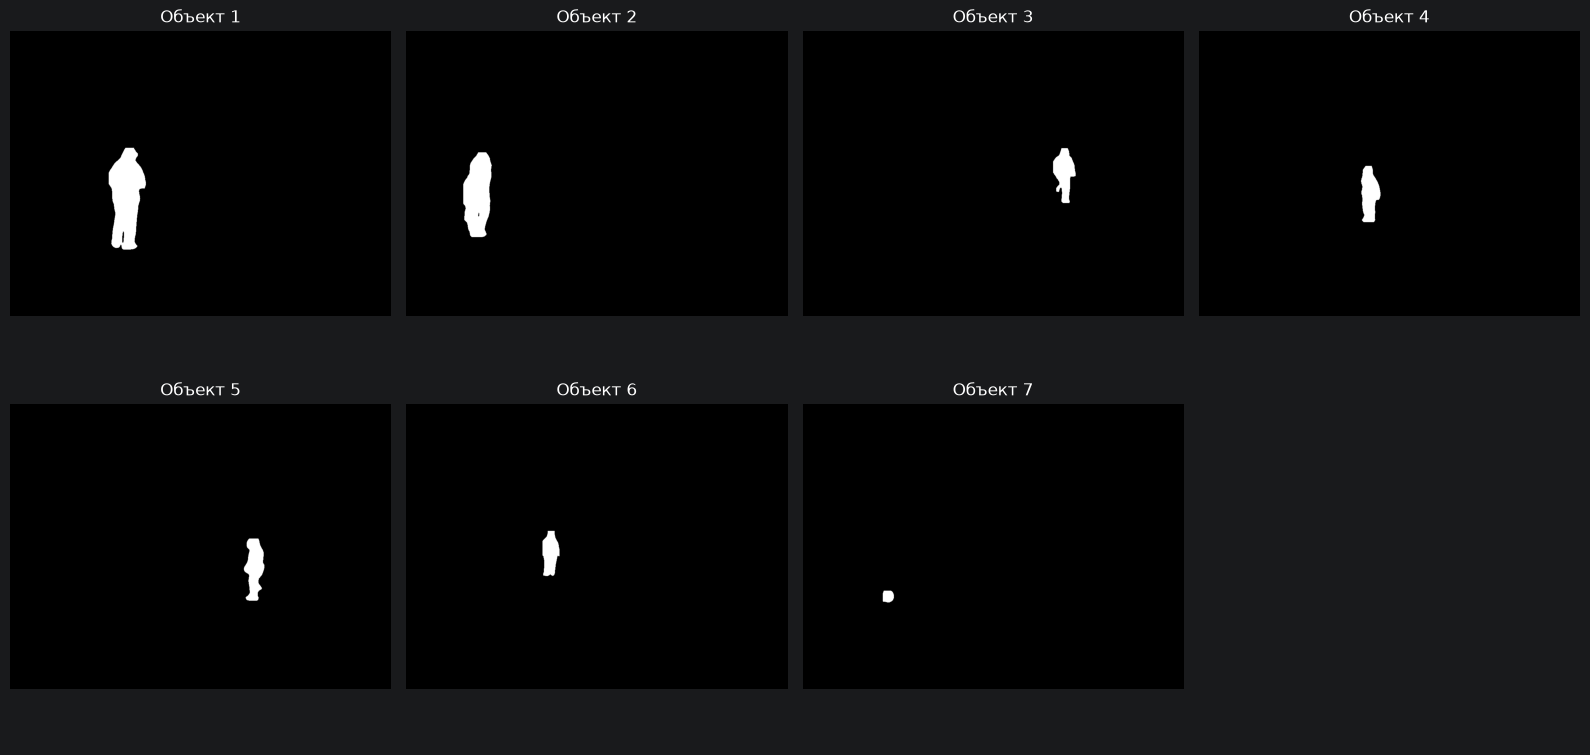

In [11]:
# Выводим отдельно маски от изображения
masks = results2[0].masks.data.cpu().numpy()

fig, ax = plt.subplots(2, 4, figsize=(16, 8))

for i, (axis, object_mask) in enumerate(zip(ax.flat, masks)):
    axis.imshow(object_mask, cmap='gray')
    axis.set_title(f'Объект {i + 1}')
    axis.axis('off')

ax[1, 3].axis('off')
plt.tight_layout()
plt.show()

In [12]:
# Сравниваем размеры
original2 = results2[0].orig_img
print(original2.shape, masks.shape)
print(masks.dtype, masks.min(), masks.max())

(822, 1097, 3) (7, 822, 1097)
uint8 0 1


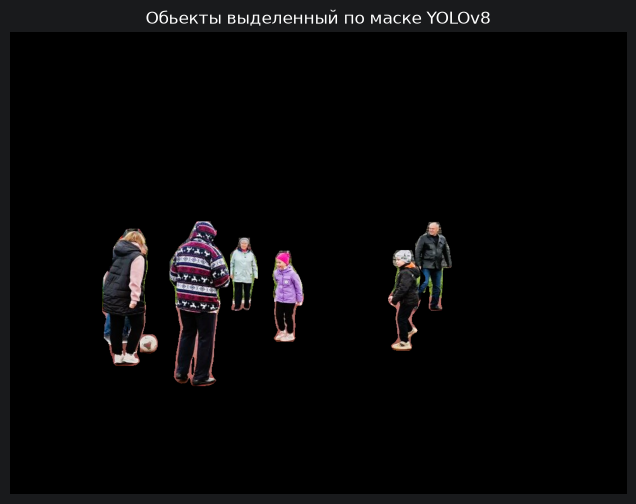

In [13]:
# Выводим все обьекты на черный фон
combined_mask = masks.max(axis=0)

objects_image = cv2.bitwise_and(original2, original2, mask=combined_mask)
objects_image = cv2.cvtColor(objects_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(objects_image)
plt.title('Обьекты выделенный по маске YOLOv8')
plt.axis('off')
plt.show()

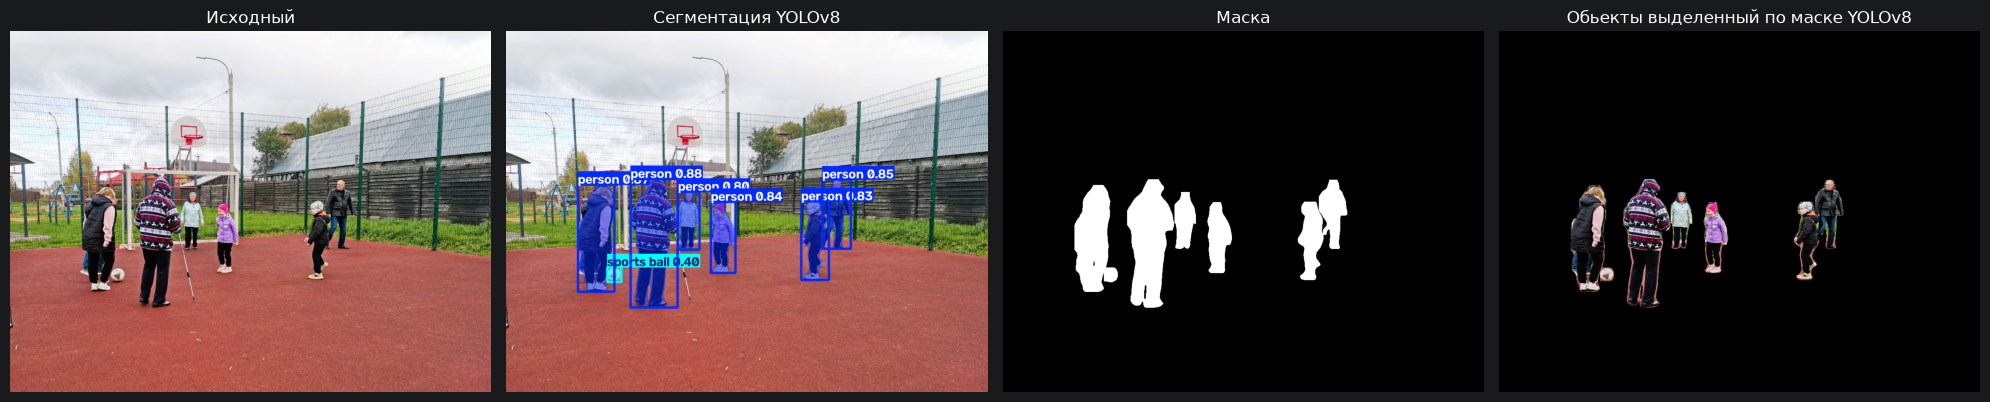

In [14]:
# Выводим вместе исходный вид, результат YOLO с наложенной маской, маску и выделенные обьекты
original2_rgb = cv2.cvtColor(results2[0].orig_img, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

ax[0].imshow(original2_rgb)
ax[0].set_title('Исходный')
ax[0].axis('off')

ax[1].imshow(annotated_image2)
ax[1].set_title('Сегментация YOLOv8')
ax[1].axis('off')

ax[2].imshow(combined_mask, cmap='gray')
ax[2].set_title('Маска')
ax[2].axis('off')

ax[3].imshow(objects_image)
ax[3].set_title('Обьекты выделенный по маске YOLOv8')
ax[3].axis('off')

plt.tight_layout()
plt.show()